# Day 3 — Track D: Error Analysis

## Goal

Analyze where the current strongest regression model makes mistakes.

We focus on:

- Large prediction errors.
- Residual patterns.
- Overprediction and underprediction.
- Differences in error across cities and listing types.

The analysis uses out-of-fold predictions on the shared training data, so the test set remains untouched for final evaluation.

## Step 1 — Import libraries and the shared preprocessing pipeline

We reuse the same preprocessing version and model setup selected in the previous model-comparison notebook.

The selected preprocessing version is V2.1.
The current strongest candidate is HistGradientBoostingRegressor.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline

from preprocessing import preprocessor_v21, FEATURES_V21

pd.set_option("display.float_format", "{:,.2f}".format)

## Step 2 — Define shared project settings

We use exactly the same processed dataset, training split, target definition, currency conversion, and random seed as the previous modeling work.

The target is `price_eur`, so prices from all five cities are evaluated in the same currency.

In [2]:
DATA_PATH = Path("../data/processed/hostwise_5cities.csv")
SPLIT_DIR = Path("../data/splits")

CITIES = [
    "london",
    "paris",
    "rome",
    "madrid",
    "barcelona"
]

TARGET = "price_eur"
GBP_TO_EUR = 1.15
RANDOM_STATE = 42

## Step 3 — Load the shared training data

We rebuild the same `price_eur` target used in the previous modeling notebook.

Only the saved training IDs are loaded.

The test set is intentionally not used during this error analysis.

In [3]:
split_config = json.loads(
    (SPLIT_DIR / "split_config_eur.json").read_text()
)

df = pd.read_csv(
    DATA_PATH,
    low_memory=False,
    dtype={"id": "int64"}
).set_index("id")

df["price_num"] = pd.to_numeric(
    df["price"].astype(str).str.replace(r"[$,]", "", regex=True),
    errors="coerce"
)

df[TARGET] = (
    df["price_num"]
    * np.where(df["city"] == "london", GBP_TO_EUR, 1.0)
)

train_ids = pd.read_csv(
    SPLIT_DIR / "train_ids_eur.csv",
    dtype={"id": "int64"}
)["id"]

train_df = df.loc[train_ids].copy()

print("Training rows:", len(train_df))
print("Target:", TARGET)
print("Missing target values:", train_df[TARGET].isna().sum())

Training rows: 123049
Target: price_eur
Missing target values: 0


## Step 4 — Recreate the shared cross-validation folds

We use the same 5-fold cross-validation strategy as the previous model comparison.

The folds are stratified by city so that each fold contains a similar city distribution.

Using the same folds makes the error analysis consistent with the previous evaluation.

In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

folds = list(
    cv.split(train_df, train_df["city"])
)

print("Number of folds:", len(folds))

Number of folds: 5


## Step 5 — Rebuild the strongest current model pipeline

The current strongest candidate from the previous model comparison is:

HistGradientBoostingRegressor + preprocessing V2.1.

Preprocessing stays inside the full pipeline so that it is fitted separately inside each cross-validation fold and does not introduce data leakage.

In [5]:
model = HistGradientBoostingRegressor(
    random_state=RANDOM_STATE
)

pipeline = Pipeline([
    ("preprocessor", clone(preprocessor_v21)),
    ("model", model)
])

features = FEATURES_V21

print("Number of model features:", len(features))
print(features)

Number of model features: 16
['accommodates', 'latitude', 'longitude', 'beds', 'minimum_nights', 'hosts_time_as_host_years', 'bedrooms', 'review_scores_rating', 'number_of_reviews', 'calculated_host_listings_count', 'bathrooms_text', 'city', 'room_type', 'property_type', 'neighbourhood_cleansed', 'host_is_superhost']


## Step 6 — Generate out-of-fold predictions

We generate one prediction for every training listing using cross-validation.

Each prediction is made by a model that was not trained on that listing.

This gives us realistic predictions for error analysis without using the final test set.

In [6]:
X = train_df[features]
y = train_df[TARGET]

y_pred = cross_val_predict(
    pipeline,
    X,
    y,
    cv=folds,
    n_jobs=-1
)

# Keep predicted prices non-negative
y_pred = np.clip(y_pred, 0, None)

print("Predictions created:", len(y_pred))
print("Actual values:", len(y))

Predictions created: 123049
Actual values: 123049


## Step 7 — Calculate prediction errors

For every listing, we calculate:

- Actual price.
- Predicted price.
- Residual.
- Absolute error.

Residual is defined as:

actual price - predicted price

Therefore:

- Positive residual = underprediction.
- Negative residual = overprediction.

In [7]:
error_df = train_df.copy()

error_df["actual_price_eur"] = y.values
error_df["predicted_price_eur"] = y_pred

error_df["residual"] = (
    error_df["actual_price_eur"]
    - error_df["predicted_price_eur"]
)

error_df["absolute_error"] = (
    error_df["residual"].abs()
)

error_df["prediction_direction"] = np.where(
    error_df["residual"] > 0,
    "Underprediction",
    np.where(
        error_df["residual"] < 0,
        "Overprediction",
        "Exact"
    )
)

error_df[
    [
        "actual_price_eur",
        "predicted_price_eur",
        "residual",
        "absolute_error",
        "prediction_direction"
    ]
].head()

,actual_price_eur,predicted_price_eur,residual,absolute_error,prediction_direction
id,,,,,
1339822709246176705,291.00,282.36,8.64,8.64,Underprediction
1638177765178487644,478.18,330.36,147.82,147.82,Underprediction
12896531,358.00,329.80,28.20,28.20,Underprediction
1262318958906657660,241.50,199.94,41.56,41.56,Underprediction
1649222827954135613,722.20,920.30,-198.10,198.10,Overprediction


## Step 8 — Overall error summary

Before investigating individual mistakes, we calculate the overall model performance.

MAE remains the primary metric because it directly represents the average absolute prediction error in euros.

In [8]:
mae = mean_absolute_error(
    error_df["actual_price_eur"],
    error_df["predicted_price_eur"]
)

rmse = mean_squared_error(
    error_df["actual_price_eur"],
    error_df["predicted_price_eur"]
) ** 0.5

r2 = r2_score(
    error_df["actual_price_eur"],
    error_df["predicted_price_eur"]
)

mean_residual = error_df["residual"].mean()

print(f"MAE: {mae:,.2f} EUR")
print(f"RMSE: {rmse:,.2f} EUR")
print(f"R²: {r2:,.3f}")
print(f"Mean residual: {mean_residual:,.2f} EUR")

MAE: 118.59 EUR
RMSE: 604.07 EUR
R²: 0.186
Mean residual: -0.27 EUR


## Step 9 — Inspect the largest prediction errors

We inspect the listings with the largest absolute errors.

This helps identify individual cases where the model struggles most and whether those cases share common characteristics.

In [9]:
columns_to_show = [
    "city",
    "room_type",
    "property_type",
    "accommodates",
    "bedrooms",
    "bathrooms",
    "actual_price_eur",
    "predicted_price_eur",
    "residual",
    "absolute_error",
    "prediction_direction"
]

largest_errors = (
    error_df[columns_to_show]
    .sort_values("absolute_error", ascending=False)
    .head(20)
)

display(largest_errors)

,city,room_type,property_type,accommodates,bedrooms,bathrooms,actual_price_eur,predicted_price_eur,residual,absolute_error,prediction_direction
id,,,,,,,,,,,
1073735761485091887,paris,Entire home/apt,Entire home,7,4.00,1.00,"97,003.05",393.61,"96,609.44","96,609.44",Underprediction
13254774,london,Private room,Private room in rental unit,1,NaN,1.00,"86,250.00",143.51,"86,106.49","86,106.49",Underprediction
1140015032188028758,paris,Entire home/apt,Entire rental unit,6,3.00,2.00,"70,080.00",812.03,"69,267.97","69,267.97",Underprediction
53056104,madrid,Entire home/apt,Entire rental unit,6,3.00,1.50,"36,883.00","1,603.51","35,279.49","35,279.49",Underprediction
7447891,paris,Entire home/apt,Entire condo,2,1.00,1.00,"34,240.00",183.30,"34,056.70","34,056.70",Underprediction
1203041287118705621,london,Private room,Private room in rental unit,3,NaN,1.00,"32,200.00",185.93,"32,014.07","32,014.07",Underprediction
1183168933886992107,london,Private room,Private room in rental unit,3,NaN,1.00,"27,238.90",304.97,"26,933.93","26,933.93",Underprediction
1123113027320058721,paris,Entire home/apt,Entire rental unit,4,1.00,1.00,"24,949.00",298.34,"24,650.66","24,650.66",Underprediction
34570478,madrid,Entire home/apt,Entire loft,1,1.00,1.00,"22,832.50",106.88,"22,725.62","22,725.62",Underprediction


### Step 9 Findings

- The largest prediction errors are dominated by extreme high-price listings.
- The model strongly underpredicts these listings.
- Several actual prices are tens of thousands of euros, while the model predicts values in the hundreds or low thousands.
- These extreme cases help explain why RMSE is much larger than MAE.
- The extreme prices should be investigated further to determine whether they are valid luxury listings or potential data-quality outliers.

## Step 10 — Compare overprediction and underprediction

We examine whether the model more often predicts prices that are too high or too low.

We also compare the average error size for both types of mistakes.

In [10]:
direction_summary = (
    error_df
    .groupby("prediction_direction")
    .agg(
        listings=("absolute_error", "size"),
        mean_absolute_error=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_residual=("residual", "mean")
    )
)

display(direction_summary)

,listings,mean_absolute_error,median_absolute_error,mean_residual
prediction_direction,,,,
Overprediction,78563,93.08,53.07,-93.08
Underprediction,44486,163.63,50.69,163.63


## Step 11 — Error by city

We compare prediction errors across the five cities.

This helps answer whether the model performs equally well across markets or struggles more in particular cities.

In [11]:
city_errors = (
    error_df
    .groupby("city")
    .agg(
        listings=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_residual=("residual", "mean")
    )
    .sort_values("MAE", ascending=False)
)

display(city_errors)

,listings,MAE,median_absolute_error,mean_residual
city,,,,
paris,31495,157.85,66.73,0.83
london,47048,120.67,56.20,-0.87
madrid,13005,106.69,39.56,-5.24
barcelona,6481,90.42,49.81,11.54
rome,25020,78.73,41.58,-1.01


## Step 12 — Visualize MAE by city

A bar chart makes the differences in prediction error between cities easier to communicate in the final presentation.

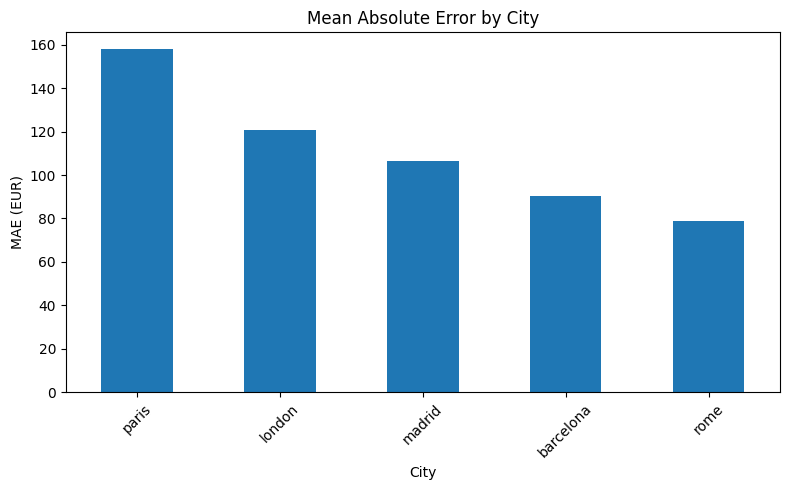

In [12]:
city_errors["MAE"].plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Mean Absolute Error by City")
plt.ylabel("MAE (EUR)")
plt.xlabel("City")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Step 13 — Error by room type

We compare prediction error across room types.

This helps determine whether certain accommodation types are more difficult for the model to price accurately.

In [13]:
room_type_errors = (
    error_df
    .groupby("room_type")
    .agg(
        listings=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_residual=("residual", "mean")
    )
    .sort_values("MAE", ascending=False)
)

display(room_type_errors)

,listings,MAE,median_absolute_error,mean_residual
room_type,,,,
Entire home/apt,94209,127.36,59.97,0.70
Hotel room,556,113.54,57.87,9.05
Shared room,470,89.93,42.00,-47.12
Private room,27814,89.47,32.80,-2.94


## Step 14 — Error by property type

`property_type` contains many categories.

To avoid drawing conclusions from very small groups, we only compare property types with at least 100 listings.

In [14]:
property_errors = (
    error_df
    .groupby("property_type")
    .agg(
        listings=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        median_absolute_error=("absolute_error", "median"),
        mean_residual=("residual", "mean")
    )
)

property_errors = (
    property_errors[
        property_errors["listings"] >= 100
    ]
    .sort_values("MAE", ascending=False)
)

display(property_errors.head(15))

,listings,MAE,median_absolute_error,mean_residual
property_type,,,,
Entire villa,113,764.52,415.66,108.33
Entire townhouse,590,251.55,118.82,16.69
Room in hotel,1861,209.97,77.16,13.13
Entire home,5739,208.26,91.76,7.12
Entire serviced apartment,2050,157.62,76.16,20.00
Room in boutique hotel,674,146.94,66.93,34.23
Entire loft,1101,130.39,51.83,10.21
Entire rental unit,72890,122.74,59.07,-1.44
Private room in guesthouse,432,119.08,38.45,-1.06


## Step 15 — Check residual patterns

A residual plot helps detect systematic patterns in prediction errors.

A well-behaved model should have residuals distributed around zero without a strong pattern.

A visible pattern may indicate that the model performs differently at different price levels.

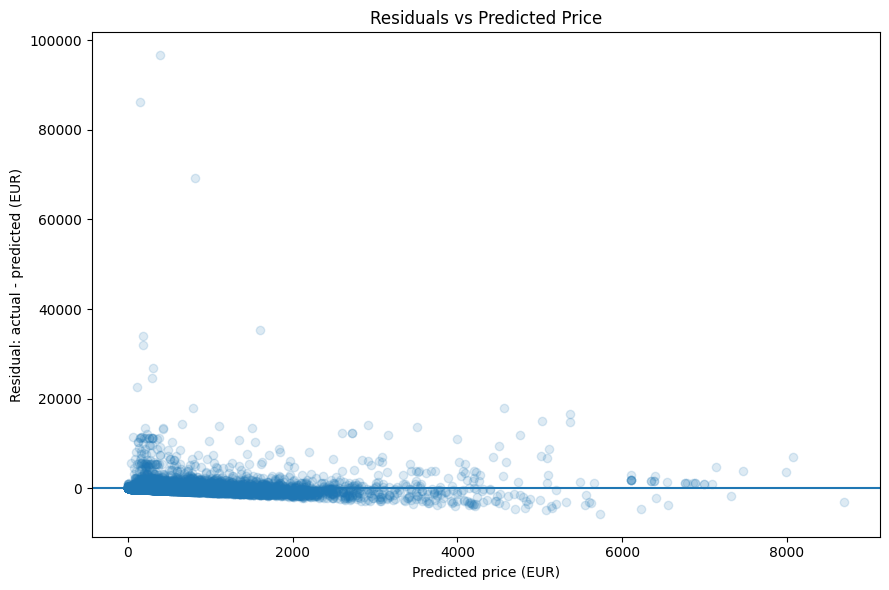

In [15]:
plt.figure(figsize=(9, 6))

plt.scatter(
    error_df["predicted_price_eur"],
    error_df["residual"],
    alpha=0.15
)

plt.axhline(0)

plt.xlabel("Predicted price (EUR)")
plt.ylabel("Residual: actual - predicted (EUR)")
plt.title("Residuals vs Predicted Price")

plt.tight_layout()
plt.show()

## Step 16 — Compare actual and predicted prices

We compare actual prices with predicted prices.

Perfect predictions would fall on the diagonal reference line.

Listings far from the diagonal represent larger prediction errors.

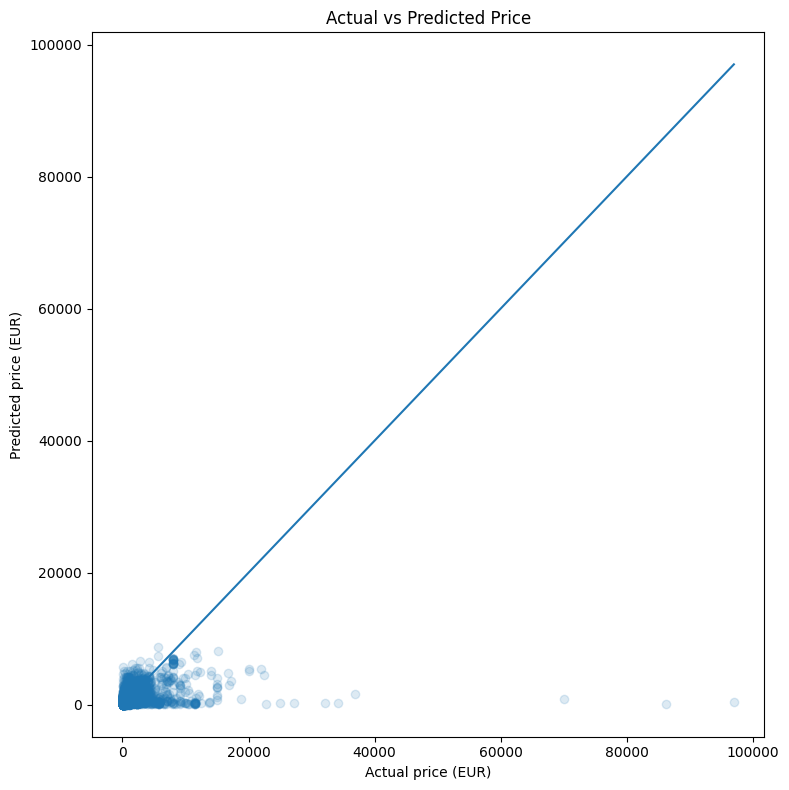

In [16]:
plt.figure(figsize=(8, 8))

plt.scatter(
    error_df["actual_price_eur"],
    error_df["predicted_price_eur"],
    alpha=0.15
)

max_value = max(
    error_df["actual_price_eur"].max(),
    error_df["predicted_price_eur"].max()
)

plt.plot(
    [0, max_value],
    [0, max_value]
)

plt.xlabel("Actual price (EUR)")
plt.ylabel("Predicted price (EUR)")
plt.title("Actual vs Predicted Price")

plt.tight_layout()
plt.show()

## Step 17 — Error by price level

We divide listings into price groups based on the actual price distribution.

This helps determine whether the model performs differently for cheaper and more expensive listings.

In [17]:
error_df["price_group"] = pd.qcut(
    error_df["actual_price_eur"],
    q=5,
    duplicates="drop"
)

price_group_errors = (
    error_df
    .groupby("price_group", observed=True)
    .agg(
        listings=("absolute_error", "size"),
        mean_actual_price=("actual_price_eur", "mean"),
        MAE=("absolute_error", "mean"),
        mean_residual=("residual", "mean")
    )
)

display(price_group_errors)

,listings,mean_actual_price,MAE,mean_residual
price_group,,,,
"(7.029, 113.85]",24651,82.08,62.07,-57.08
"(113.85, 165.47]",24596,138.56,60.86,-52.68
"(165.47, 232.875]",24584,197.11,64.51,-44.11
"(232.875, 360.0]",24651,287.62,82.29,-25.83
"(360.0, 97003.05]",24567,760.47,323.63,178.72


## Step 18 — Identify the main error patterns

We summarize the evidence collected from the previous analyses.

The goal is not only to report the model's error, but to explain where the model struggles.

Questions to answer:

1. Which city has the highest MAE?
2. Which room types are hardest to predict?
3. Which common property types have large errors?
4. Does the model struggle more with expensive listings?
5. Does the model tend to overpredict or underpredict?
6. Are there clear patterns in the residual plot?

### Findings

- The model has the largest MAE in **Paris**.
- Errors increase for **higher-priced listings, especially the most expensive price group**.
- The model **overpredicts more often overall, but the largest errors come from strong underprediction of expensive listings**.
- **Entire home/apt** listings show larger errors than the other room types, followed by **Hotel room**.
- Among property types with at least 100 listings, **Entire villa** has the highest MAE, although this group contains only 113 listings and should be interpreted cautiously.
- The residual plot shows a clear pattern: **extreme positive residuals occur when very expensive listings are predicted far too low**, indicating strong underprediction of extreme prices.
- The largest individual errors are mostly associated with **extremely high-priced listings that the model strongly underpredicts, especially in Paris and London**.

## Track D — Error Analysis Summary

The error analysis shows that the model performs reasonably for many normal-priced listings, but struggles with extreme high-price listings.

Key findings:

- Paris has the highest MAE among the five cities.
- Prediction errors increase substantially for the highest-priced listings.
- Overprediction happens more often overall, but the largest errors are caused by strong underprediction of expensive listings.
- Entire home/apt listings have the highest MAE among room types.
- Extreme high-price listings are the main source of the largest individual errors.

These findings suggest that future model improvements should focus on handling extreme prices and improving predictions for expensive listings.